In [1]:
import pandas as pd

df = pd.read_csv("../data/Reviews.csv", usecols=["Score", "Text"])
df = df.drop_duplicates(subset="Text")   # is dataset mein same review kai baar repeat hota hai

def score_to_label(score):
    if score >= 4:
        return "Positive"
    elif score == 3:
        return "Neutral"
    else:
        return "Negative"

df["label"] = df["Score"].apply(score_to_label)
print(df["label"].value_counts())

n = min(df["label"].value_counts().min(), 40000)
balanced = df.groupby("label").sample(n=n, random_state=42).reset_index(drop=True)
print("Per class:", n)
print(balanced["label"].value_counts())

label
Positive    306758
Negative     57067
Neutral      29754
Name: count, dtype: int64
Per class: 29754
label
Negative    29754
Neutral     29754
Positive    29754
Name: count, dtype: int64


In [2]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

# "not", "no" jaise words rakhne hain, kyunki inse sentiment badalta hai
stop_words = set(stopwords.words("english")) - {"not", "no", "nor", "never", "but", "very", "too"}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)        # HTML tags
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "can not", text)
    text = re.sub(r"n't\b", " not", text)     # don't -> do not
    text = re.sub(r"[^a-z\s]", " ", text)     # sirf letters rakho
    words = [w for w in text.split() if w not in stop_words]
    return " ".join(words)

print(clean_text("The battery is NOT good, I can't recommend it!<br />Very disappointed."))

battery not good not recommend very disappointed


[nltk_data] Downloading package stopwords to C:\Users\Abhishek
[nltk_data]     Gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
balanced["clean_text"] = balanced["Text"].apply(clean_text)
balanced[["Text", "clean_text", "label"]].head()

,Text,clean_text,label
0,This is perfetly identical to Jiffy peanutbutt...,perfetly identical jiffy peanutbutter blind ta...,Negative
1,They taste more like chemicals than meat. I l...,taste like chemicals meat like lot jerky meat ...,Negative
2,"Chips were OK, just didn't have enough dill an...",chips ok not enough dill cucumber flavor very ...,Negative
3,Very disappointed to receive a case of food pr...,very disappointed receive case food product fr...,Negative
4,"I absolutely hate the taste of this tea, but i...",absolutely hate taste tea but would work would...,Negative


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    balanced["clean_text"],
    balanced["label"],
    test_size=0.2,
    random_state=42,
    stratify=balanced["label"]
)
print(len(X_train), len(X_test))

71409 17853


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000)

X_train_vec = tfidf.fit_transform(X_train)   # train pe fit + transform
X_test_vec = tfidf.transform(X_test)         # test pe SIRF transform

print(X_train_vec.shape)
print("not good" in tfidf.vocabulary_)
print(tfidf.get_feature_names_out()[:30])

(71409, 50000)
True
['aa' 'aafco' 'ab' 'aback' 'abandoned' 'abc' 'abdominal' 'abdominal pain'
 'ability' 'able' 'able add' 'able buy' 'able chew' 'able drink'
 'able eat' 'able enjoy' 'able find' 'able finish' 'able get' 'able give'
 'able go' 'able handle' 'able keep' 'able make' 'able order' 'able pick'
 'able provide' 'able purchase' 'able return' 'able save']


In [6]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_vec, y_train)
print("Training complete")

Training complete


In [7]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model_lr.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.7258

              precision    recall  f1-score   support

    Negative       0.73      0.73      0.73      5951
     Neutral       0.64      0.64      0.64      5951
    Positive       0.81      0.81      0.81      5951

    accuracy                           0.73     17853
   macro avg       0.73      0.73      0.73     17853
weighted avg       0.73      0.73      0.73     17853



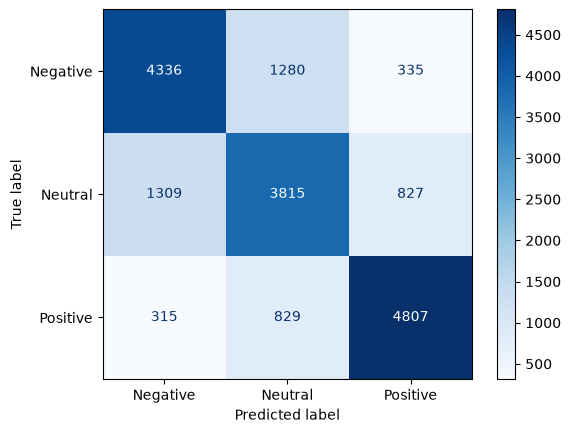

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")

In [9]:
import numpy as np

feature_names = tfidf.get_feature_names_out()
for i, cls in enumerate(model_lr.classes_):
    top = np.argsort(model_lr.coef_[i])[-10:][::-1]
    print(cls, "->", [feature_names[j] for j in top])
    print()

Negative -> ['terrible', 'worst', 'awful', 'very disappointed', 'not recommend', 'not', 'two stars', 'not good', 'threw', 'horrible']

Neutral -> ['however', 'but', 'ok', 'three stars', 'okay', 'not bad', 'stars', 'average', 'decent', 'not best']

Positive -> ['great', 'delicious', 'perfect', 'best', 'not disappointed', 'excellent', 'love', 'loves', 'wonderful', 'not too']



In [11]:
tests = [
    "The delivery was very late and the food was cold",
    "Absolutely loved it, great taste and fast shipping",
    "It was okay, nothing special",
    "Phone camera is amazing but battery is terrible",
    "Staff was helpful and polite",
]

for t in tests:
    pred = model_lr.predict(tfidf.transform([clean_text(t)]))[0]
    print(f"{pred:9} <- {t}")

Positive  <- The delivery was very late and the food was cold
Positive  <- Absolutely loved it, great taste and fast shipping
Neutral   <- It was okay, nothing special
Negative  <- Phone camera is amazing but battery is terrible
Positive  <- Staff was helpful and polite


In [12]:
from sklearn.svm import LinearSVC

model_svm = LinearSVC(random_state=42)
model_svm.fit(X_train_vec, y_train)

y_pred_svm = model_svm.predict(X_test_vec)
print("SVM Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print(classification_report(y_test, y_pred_svm))

SVM Accuracy: 0.7102
              precision    recall  f1-score   support

    Negative       0.71      0.72      0.71      5951
     Neutral       0.63      0.61      0.62      5951
    Positive       0.79      0.80      0.80      5951

    accuracy                           0.71     17853
   macro avg       0.71      0.71      0.71     17853
weighted avg       0.71      0.71      0.71     17853



In [13]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")
joblib.dump(model_lr, "../models/sentiment_lr.pkl")
print("Saved")

Saved


In [14]:
tfidf_loaded = joblib.load("../models/tfidf_vectorizer.pkl")
model_loaded = joblib.load("../models/sentiment_lr.pkl")

text = "Terrible quality, it broke in two days"
vec = tfidf_loaded.transform([clean_text(text)])
print(model_loaded.predict(vec)[0])
print(dict(zip(model_loaded.classes_, model_loaded.predict_proba(vec)[0].round(3))))

Negative
{'Negative': np.float64(0.971), 'Neutral': np.float64(0.018), 'Positive': np.float64(0.011)}
